Name Haoxin Ni

Labpartner(s)

In [1]:
#import statements go here
#import statements go here
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs   #import map styles/types|
import cartopy.feature as cfeature  # features such as the ocean, coastlines rivers, etc

# Class 7.1

Today we are going to go over cartopy a bit more and you will start the Pandas course in Datacamp.

I'm also going to go over the final project. Your topic (like a few sentances) is due this comeing Sunday 10/11

# Warmups 7.1

**W.1** Play around with some map projections in cartopy. 

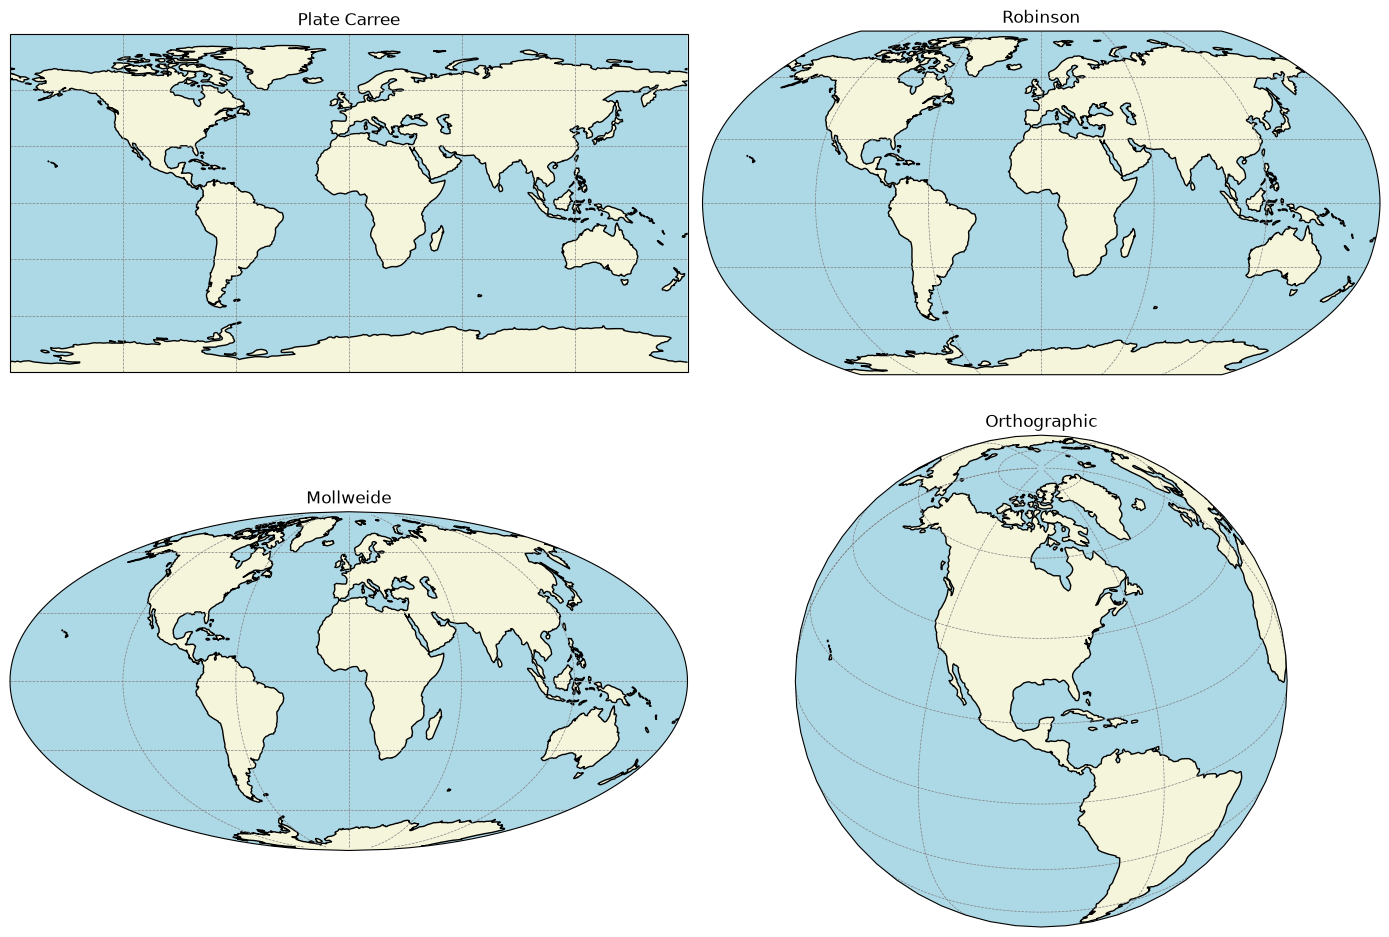

In [2]:
# Compare four map projections
projections = [
    ("Plate Carree", ccrs.PlateCarree()),
    ("Robinson", ccrs.Robinson()),
    ("Mollweide", ccrs.Mollweide()),
    ("Orthographic", ccrs.Orthographic(
        central_longitude=-90, central_latitude=30
    ))
]

fig = plt.figure(figsize=(14, 10))

for i, (name, projection) in enumerate(projections):
    ax = fig.add_subplot(2, 2, i + 1, projection=projection)
    ax.set_global()

    ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
    ax.add_feature(cfeature.LAND, facecolor="beige")
    ax.coastlines()
    ax.gridlines(linewidth=0.5, color="gray", linestyle="--")
    ax.set_title(name)

plt.tight_layout()
plt.show()

**W.2** Make a nice map of Antarctica. Label McMurdo Station

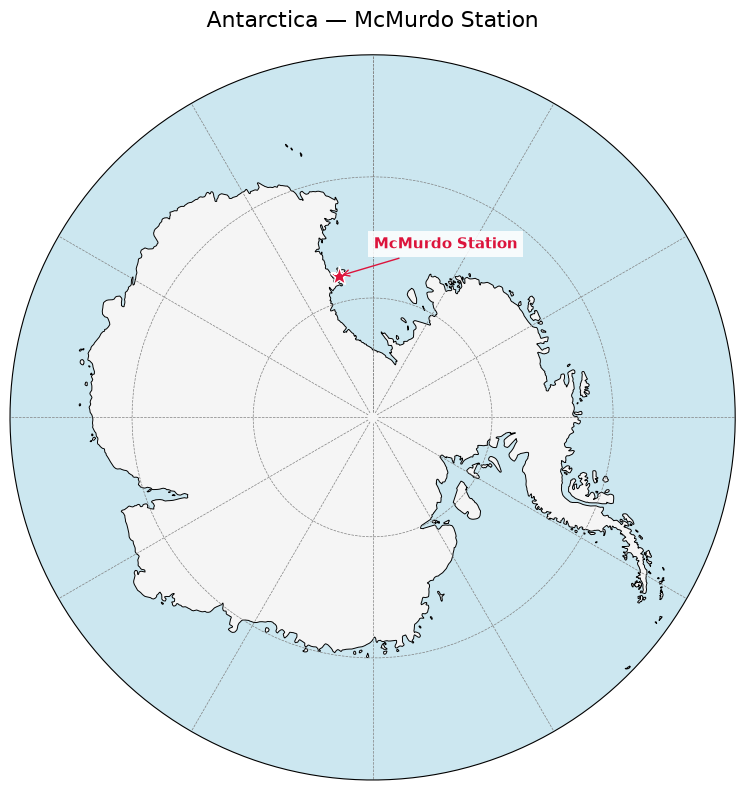

In [3]:
import matplotlib.path as mpath

# Create a map centered on the South Pole
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(
    111,
    projection=ccrs.SouthPolarStereo(central_longitude=180)
)

# Set the map extent in projected coordinates (meters)
ax.set_extent(
    [-3400000, 3400000, -3400000, 3400000],
    crs=ax.projection
)

# Make the map boundary circular
theta = np.linspace(0, 2 * np.pi, 200)
circle = mpath.Path(
    np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5
)
ax.set_boundary(circle, transform=ax.transAxes)

# Add land, ocean color, coastlines, and gridlines
ax.set_facecolor("#cce7f0")
ax.add_feature(cfeature.LAND, facecolor="#f5f5f5")
ax.coastlines(linewidth=0.7)
ax.gridlines(
    xlocs=np.arange(-180, 181, 30),
    ylocs=[-80, -70, -60],
    linewidth=0.5,
    color="gray",
    linestyle="--"
)

# Mark McMurdo Station using longitude and latitude
lon = 166.67
lat = -77.85

ax.plot(
    lon, lat,
    marker="*", markersize=14,
    color="crimson", markeredgecolor="white",
    transform=ccrs.PlateCarree(),
    zorder=5
)

# Convert the station's coordinates for the annotation
x, y = ax.projection.transform_point(lon, lat, ccrs.PlateCarree())

ax.annotate(
    "McMurdo Station",
    xy=(x, y),
    xytext=(25, 20),
    textcoords="offset points",
    fontsize=11,
    color="crimson",
    fontweight="bold",
    arrowprops=dict(arrowstyle="->", color="crimson"),
    bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"),
    zorder=6
)

ax.set_title("Antarctica — McMurdo Station", fontsize=16, pad=20)
plt.tight_layout()
plt.show()

# i googled and find a good map

# Lecture 7.1

### Agenda:

- Questions
- Final project (see github for rubrics, and 2024 class for samples)
    - Project topics due this Sunday 10/11. I will discuss this with you to make sure it's not overly ambitious.
    - Proposal due 10/25. We will do peer review on this
    - Topics presentations 10/26, we will give feedback
    - Weekly reports become project focused in a few weeks
    - Final report is due 12/10
    - Final presentation during Final period 12/11 12:30-2:30
  

### Questions

# Lab 7.1

**E.1** Complete Data Manipulation with Pandas Ch 1-2 in datacamp. I'm assigning all of this course to the class, as many of you have .csv type data that works well with Pandas. If you don't have data that Pandas is useful for, come see me and we can talk about an alternate assignment.


**E.2** Make notes for yourself on progamming tecniques and commands you learned in the datacamp chapter above, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

Chapter 1 was mostly about changing and selecting data. Chapter 2 was about summarizing it. These are the commands I want to remember. The examples below use the `homelessness` and `sales` DataFrames from DataCamp.

**1. Check the data first**

```python
homelessness.head()      # first five rows
homelessness.info()      # column types and non-missing values
homelessness.shape       # number of rows and columns; no () here
homelessness.describe()  # basic statistics for numerical columns
homelessness.columns    # column names
homelessness.index      # row labels
homelessness.to_numpy()  # values as an array, without the labels
```

`info()` already prints its result, so I don't need to put it inside `print()`.

**2. Select columns and filter rows**

```python
homelessness["individuals"]                   # one column: a Series
homelessness[["state", "individuals"]]        # multiple columns: a DataFrame
homelessness[homelessness["individuals"] > 10000]

# Each condition needs its own parentheses. & means "and".
homelessness[(homelessness["region"] == "Pacific") &
             (homelessness["family_members"] < 1000)]

# isin() is easier than writing lots of "or" conditions
homelessness[homelessness["state"].isin(["California", "Nevada"])]
```

The main thing to remember is the double brackets when selecting several columns.

**3. Sort rows and add columns**

```python
# Default sorting is smallest to largest
homelessness.sort_values("individuals", ascending=False)
homelessness.sort_values(["region", "family_members"], ascending=[True, False])

homelessness["total"] = homelessness["individuals"] + homelessness["family_members"]
homelessness["p_homeless"] = homelessness["total"] / homelessness["state_pop"]
```

Calculations work on the whole column, so I don't need a loop. I can combine adding a column, filtering, sorting, and selecting columns to answer a question.

**4. Calculate statistics**

```python
sales["weekly_sales"].mean()
sales["weekly_sales"].median()
sales["weekly_sales"].agg(["min", "max", "mean", "median"])
sales["date"].min()  # earliest date; max() gives the latest

def iqr(column):
    # Difference between the 75th and 25th percentiles
    return column.quantile(0.75) - column.quantile(0.25)

sales["weekly_sales"].agg([iqr, "median"])
```

The mean can be pulled up by a few very large values. `agg()` is useful when I want several statistics at once, including my own function.

**5. Cumulative values**

```python
sales_1_1 = sales_1_1.sort_values("date")  # put one store/department in time order
sales_1_1["cum_sales"] = sales_1_1["weekly_sales"].cumsum()
sales_1_1["cum_max"] = sales_1_1["weekly_sales"].cummax()
```

These give a value for every row. `cumsum()` keeps a running total, and `cummax()` keeps the largest value seen so far.

**6. Remove duplicates and count categories**

```python
stores = sales.drop_duplicates(subset=["store", "type"])
stores["type"].value_counts()                # number of stores of each type
stores["type"].value_counts(normalize=True)  # proportions instead of counts
```

One store has many sales records, so counting rows is different from counting stores. I need to choose the right columns when removing duplicates.

**7. Groupby and pivot tables**

```python
sales.groupby("type")["weekly_sales"].sum()
sales.groupby(["type", "is_holiday"])["weekly_sales"].mean()
sales.groupby("type")["weekly_sales"].agg(["min", "max", "mean"])

sales.pivot_table(values="weekly_sales", index="type",
                  columns="is_holiday", aggfunc="mean", margins=True)
```

`groupby()` saves me from filtering each group separately. A pivot table puts the groups into rows and columns: `values` is what I calculate, `index` sets the rows, and `columns` sets the columns. It uses the mean by default. `fill_value=0` can fill empty cells, but missing data does not always mean zero. `margins=True` adds an overall summary using the same function, so here the `All` values are means, not sums.

**E.3** Work on brainstorming your final project. Make sure it's actually doable, please don't take on too much! The goal here is to learn some code and practice scientific communication.

### Final project idea

**Evaluating Tropical Cyclone Tracking and Parameter Sensitivity with TempestExtremes**

I plan to use TempestExtremes (TE) to track three Atlantic hurricanes from 2021—Ida, Larry, and Nicholas—in ERA5 data and compare the tracks with IBTrACS, which I used in Lab 5.2. I will start with Ida to get the workflow running, then add the other two storms. I will compare storm positions, how much of each IBTrACS track TE captures, and when the detected tracks start and end. I will also test pressure-contour thresholds of 1, 2, and 3 hPa, keeping the other settings the same, to see how the threshold affects the results.

Starting sources: [TE paper and ERA5 tracking example](https://gmd.copernicus.org/articles/14/5023/2021/) and [IBTrACS documentation](https://www.ncei.noaa.gov/products/international-best-track-archive).
